In [1]:
from pathlib import Path
import sys

print("Python:", sys.executable)
print("Working directory:", Path.cwd())
print("Project root:", Path.cwd().parent)
print("episode.py exists:", (Path.cwd().parent / "src" / "episode.py").exists())

Python: c:\Users\AKSHITA CHOUDHARY\Desktop\claris\.venv\Scripts\python.exe
Working directory: c:\Users\AKSHITA CHOUDHARY\Desktop\claris\notebooks
Project root: c:\Users\AKSHITA CHOUDHARY\Desktop\claris
episode.py exists: True


In [1]:
import requests
import pandas as pd
from pathlib import Path

In [3]:
from pathlib import Path

Path.cwd()

WindowsPath('c:/Users/AKSHITA CHOUDHARY/Desktop/claris/notebooks')

In [6]:
from pathlib import Path

print("Python is running from:")
print(Path.cwd())

print("\nWhat Python sees here:")
print([p.name for p in Path.cwd().iterdir()])

Python is running from:
c:\Users\AKSHITA CHOUDHARY\Desktop\claris\notebooks

What Python sees here:
['01_environment_check.ipynb', '02_first_vtac_waveform.ipynb', '03_vtac_channel_inventory.ipynb', 'README.md']


In [7]:
from pathlib import Path

vtac_dir = Path("../data/raw/Vtac")

print("VTaC folder exists:", vtac_dir.exists())
print("Files found:")
print([p.name for p in vtac_dir.iterdir()])

VTaC folder exists: True
Files found:
['003c13_0115.dat', '003c13_0115.hea', 'event_labels.csv', 'event_label_per_annotator.csv']


In [8]:
event_labels = pd.read_csv("../data/raw/Vtac/event_labels.csv")

print("Number of events:", len(event_labels))
event_labels.head()

Number of events: 5037


,record,event,decision
0,003c13,003c13_0115,False
1,003c13,003c13_0126,False
2,004bad,004bad_0015,False
3,004bad,004bad_1115,False
4,004bad,004bad_1426,False


In [9]:
import requests

BASE_URL = "https://physionet.org/files/vtac/1.1/annotated_waveforms"

sample_events = event_labels.head(20)

header_results = []

for _, row in sample_events.iterrows():
    record = row["record"]
    event = row["event"]

    url = f"{BASE_URL}/{record}/{event}.hea"
    response = requests.get(url)

    if response.status_code == 200:
        lines = response.text.strip().splitlines()
        header = lines[0].split()

        header_results.append({
            "record": record,
            "event": event,
            "n_signals": int(header[1]),
            "sampling_frequency": float(header[2].split("/")[0]),
            "n_samples": int(header[3]),
            "signals": [line.split()[8] for line in lines[1:]]
        })
    else:
        print(f"Could not retrieve: {event} (HTTP {response.status_code})")

print(f"Headers successfully retrieved: {len(header_results)}")

Headers successfully retrieved: 20


In [10]:
header_df = pd.DataFrame(header_results)

header_df

,record,event,n_signals,sampling_frequency,n_samples,signals
0,003c13,003c13_0115,4,250.0,90000,"[II, aVR, V, PLETH]"
1,003c13,003c13_0126,4,250.0,90000,"[II, aVR, V, PLETH]"
2,004bad,004bad_0015,6,250.0,90000,"[I, II, aVR, V, PLETH, ABP]"
3,004bad,004bad_1115,5,250.0,90000,"[II, aVR, V, PLETH, ABP]"
4,004bad,004bad_1426,5,250.0,90000,"[I, II, V, PLETH, ABP]"
5,004bad,004bad_2348,5,250.0,90000,"[I, II, V, PLETH, ABP]"
6,004f0c,004f0c_2475,6,250.0,90000,"[I, II, III, V, PLETH, ABP]"
7,004f0c,004f0c_2533,6,250.0,90000,"[I, II, III, V, PLETH, ABP]"
8,004f0c,004f0c_3642,5,250.0,90000,"[I, II, III, V, PLETH]"
9,004f0c,004f0c_3644,5,250.0,90000,"[I, II, III, V, PLETH]"


In [11]:
channel_combinations = (
    header_df["signals"]
    .apply(lambda x: tuple(x))
    .value_counts()
    .reset_index(name="count")
)

channel_combinations

,signals,count
0,"(I, II, III, V, PLETH)",8
1,"(II, aVR, V, PLETH, ABP)",4
2,"(II, aVR, V, PLETH)",3
3,"(I, II, V, PLETH, ABP)",2
4,"(I, II, III, V, PLETH, ABP)",2
5,"(I, II, aVR, V, PLETH, ABP)",1


In [12]:
sample_events = event_labels.head(100)

header_results_100 = []

for _, row in sample_events.iterrows():
    record = row["record"]
    event = row["event"]

    url = f"{BASE_URL}/{record}/{event}.hea"
    response = requests.get(url)

    if response.status_code == 200:
        lines = response.text.strip().splitlines()
        header = lines[0].split()

        header_results_100.append({
            "record": record,
            "event": event,
            "n_signals": int(header[1]),
            "sampling_frequency": float(header[2].split("/")[0]),
            "n_samples": int(header[3]),
            "signals": [line.split()[8] for line in lines[1:]]
        })

print(f"Headers successfully retrieved: {len(header_results_100)}")

Headers successfully retrieved: 100


In [13]:
header_df_100 = pd.DataFrame(header_results_100)

header_df_100["has_abp"] = header_df_100["signals"].apply(lambda x: "ABP" in x)
header_df_100["has_pleth"] = header_df_100["signals"].apply(lambda x: "PLETH" in x)

print("Total events:", len(header_df_100))
print("Events with ABP:", header_df_100["has_abp"].sum())
print("Events with PLETH:", header_df_100["has_pleth"].sum())

Total events: 100
Events with ABP: 40
Events with PLETH: 97


In [14]:
print("Sampling frequencies:")
print(header_df_100["sampling_frequency"].value_counts())

print("\nNumber of samples:")
print(header_df_100["n_samples"].value_counts())

print("\nNumber of signals:")
print(header_df_100["n_signals"].value_counts())

Sampling frequencies:
sampling_frequency
250.0    100
Name: count, dtype: int64

Number of samples:
n_samples
90000    100
Name: count, dtype: int64

Number of signals:
n_signals
5    48
4    39
6    10
3     3
Name: count, dtype: int64


In [15]:
ecg_leads = ["I", "II", "III", "aVR", "aVL", "aVF", "V"]

for lead in ecg_leads:
    count = header_df_100["signals"].apply(lambda x: lead in x).sum()
    print(f"{lead}: {count}/100")

I: 37/100
II: 100/100
III: 28/100
aVR: 63/100
aVL: 0/100
aVF: 0/100
V: 96/100


In [16]:
header_df_100["has_ecg"] = header_df_100["signals"].apply(
    lambda x: any(lead in x for lead in ecg_leads)
)

modality_summary = (
    header_df_100[["has_ecg", "has_pleth", "has_abp"]]
    .value_counts()
    .reset_index(name="count")
)

modality_summary

,has_ecg,has_pleth,has_abp,count
0,True,True,False,57
1,True,True,True,40
2,True,False,False,3


In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [2]:
from src.episode import CLARISEpisode

first_event = header_df_100.iloc[0]

episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=first_event["sampling_frequency"],
    n_samples=first_event["n_samples"],
    duration_seconds=first_event["n_samples"] / first_event["sampling_frequency"],
    alarm_sample=300 * int(first_event["sampling_frequency"]),
    signals=first_event["signals"],
    decision=bool(
        event_labels.loc[
            event_labels["event"] == first_event["event"],
            "decision"
        ].iloc[0]
    )
)

episode

NameError: name 'header_df_100' is not defined

In [2]:
from src.episode import CLARISEpisode

print(CLARISEpisode)

ModuleNotFoundError: No module named 'src'

In [3]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)
print(project_root in [Path(p) for p in sys.path if p])

c:\Users\AKSHITA CHOUDHARY\Desktop\claris
True


In [4]:
from src.episode import CLARISEpisode

print(CLARISEpisode)

<class 'src.episode.CLARISEpisode'>


In [5]:
first_event = event_labels.iloc[0]

episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=250.0,
    n_samples=90000,
    duration_seconds=360.0,
    alarm_sample=75000,
    signals=["II", "aVR", "V", "PLETH"],
    decision=first_event["decision"]
)

print(episode)

NameError: name 'event_labels' is not defined

In [6]:
import pandas as pd

event_labels = pd.read_csv("../data/raw/Vtac/event_labels.csv")

print(event_labels.shape)
print(event_labels.head())

(5037, 3)
   record        event  decision
0  003c13  003c13_0115     False
1  003c13  003c13_0126     False
2  004bad  004bad_0015     False
3  004bad  004bad_1115     False
4  004bad  004bad_1426     False


In [7]:
first_event = event_labels.iloc[0]

episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=250.0,
    n_samples=90000,
    duration_seconds=360.0,
    alarm_sample=75000,
    signals=["II", "aVR", "V", "PLETH"],
    decision=first_event["decision"]
)

print(episode)

CLARISEpisode(record='003c13', event='003c13_0115', sampling_frequency=250.0, n_samples=90000, duration_seconds=360.0, alarm_sample=75000, signals=['II', 'aVR', 'V', 'PLETH'], decision=np.False_)


In [8]:
print(episode.record)
print(episode.event)
print(episode.sampling_frequency)
print(episode.n_samples)
print(episode.duration_seconds)
print(episode.alarm_sample)
print(episode.signals)
print(episode.decision)

003c13
003c13_0115
250.0
90000
360.0
75000
['II', 'aVR', 'V', 'PLETH']
False


In [10]:
print(header_df_100.head())

NameError: name 'header_df_100' is not defined

In [11]:
import requests
import pandas as pd

header_results_100 = []

for record in event_labels["event"].head(100):
    url = f"https://physionet.org/files/vtac/1.1/waveforms/{record}.hea"
    
    response = requests.get(url)
    
    if response.status_code == 200:
        lines = response.text.strip().splitlines()
        header = lines[0].split()
        
        signal_names = []
        
        for line in lines[1:]:
            parts = line.split()
            if len(parts) >= 9:
                signal_names.append(parts[8])
        
        header_results_100.append({
            "event": record,
            "sampling_frequency": float(header[2].split("/")[0]),
            "n_samples": int(header[3]),
            "duration_seconds": int(header[3]) / float(header[2].split("/")[0]),
            "signals": signal_names
        })

header_df_100 = pd.DataFrame(header_results_100)

print(header_df_100.head())
print(header_df_100.shape)

ConnectionError: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))

In [12]:
import wfdb

header = wfdb.rdheader("../data/raw/Vtac/003c13_0115")

print("Signals:", header.sig_name)
print("Sampling frequency:", header.fs)
print("Samples:", header.sig_len)
print("Duration:", header.sig_len / header.fs)

Signals: ['II', 'aVR', 'V', 'PLETH']
Sampling frequency: 250
Samples: 90000
Duration: 360.0


In [13]:
episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=header.fs,
    n_samples=header.sig_len,
    duration_seconds=header.sig_len / header.fs,
    alarm_sample=75000,
    signals=header.sig_name,
    decision=first_event["decision"]
)

print(episode)

CLARISEpisode(record='003c13', event='003c13_0115', sampling_frequency=250, n_samples=90000, duration_seconds=360.0, alarm_sample=75000, signals=['II', 'aVR', 'V', 'PLETH'], decision=np.False_)


In [14]:
record = wfdb.rdrecord("../data/raw/Vtac/003c13_0115")

print("Waveform shape:", record.p_signal.shape)
print("Signals:", record.sig_name)
print("Sampling frequency:", record.fs)

Waveform shape: (90000, 4)
Signals: ['II', 'aVR', 'V', 'PLETH']
Sampling frequency: 250


In [15]:
print(record.p_signal.shape)
print(record.sig_name)
print(record.units)
print(record.fs)

(90000, 4)
['II', 'aVR', 'V', 'PLETH']
['mV', 'mV', 'mV', 'NU']
250


In [16]:
print(type(record.p_signal))
print(record.p_signal.shape)
print(record.p_signal[:3])

<class 'numpy.ndarray'>
(90000, 4)
[[-0.16002776  0.07500295  0.01499742  0.37890057]
 [-0.15498843  0.07000025  0.01000624  0.37890057]
 [-0.12498689  0.04998943  0.          0.37401999]]


In [17]:
import importlib
import src.episode

importlib.reload(src.episode)

from src.episode import CLARISEpisode

print(CLARISEpisode.__annotations__)

{'record': <class 'str'>, 'event': <class 'str'>, 'sampling_frequency': <class 'float'>, 'n_samples': <class 'int'>, 'duration_seconds': <class 'float'>, 'alarm_sample': <class 'int'>, 'signals': list[str], 'waveform': typing.Optional[numpy.ndarray], 'units': typing.Optional[list[str]], 'decision': typing.Optional[bool]}


In [18]:
episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=record.fs,
    n_samples=record.sig_len,
    duration_seconds=record.sig_len / record.fs,
    alarm_sample=75000,
    signals=record.sig_name,
    waveform=record.p_signal,
    units=record.units,
    decision=first_event["decision"]
)

print(episode)

CLARISEpisode(record='003c13', event='003c13_0115', sampling_frequency=250, n_samples=90000, duration_seconds=360.0, alarm_sample=75000, signals=['II', 'aVR', 'V', 'PLETH'], waveform=array([[-0.16002776,  0.07500295,  0.01499742,  0.37890057],
       [-0.15498843,  0.07000025,  0.01000624,  0.37890057],
       [-0.12498689,  0.04998943,  0.        ,  0.37401999],
       ...,
       [-0.03000154,  0.02501352, -0.01499742,  0.57592337],
       [-0.03498227,  0.01500811,  0.01000624,  0.56884653],
       [-0.03000154,  0.0050027 ,  0.02500366,  0.56884653]],
      shape=(90000, 4)), units=['mV', 'mV', 'mV', 'NU'], decision=np.False_)


In [19]:
import numpy as np

time = (np.arange(episode.n_samples) - episode.alarm_sample) / episode.sampling_frequency

print("Start:", time[0], "seconds")
print("Alarm:", time[episode.alarm_sample], "seconds")
print("End:", time[-1], "seconds")
print("Number of time points:", len(time))

Start: -300.0 seconds
Alarm: 0.0 seconds
End: 59.996 seconds
Number of time points: 90000


In [20]:
import importlib
import src.episode

importlib.reload(src.episode)

from src.episode import CLARISEpisode

print(CLARISEpisode.__annotations__)

{'record': <class 'str'>, 'event': <class 'str'>, 'sampling_frequency': <class 'float'>, 'n_samples': <class 'int'>, 'duration_seconds': <class 'float'>, 'alarm_sample': <class 'int'>, 'signals': list[str], 'waveform': typing.Optional[numpy.ndarray], 'time': typing.Optional[numpy.ndarray], 'units': typing.Optional[list[str]], 'decision': typing.Optional[bool]}


In [21]:
episode = CLARISEpisode(
    record=first_event["record"],
    event=first_event["event"],
    sampling_frequency=record.fs,
    n_samples=record.sig_len,
    duration_seconds=record.sig_len / record.fs,
    alarm_sample=75000,
    signals=record.sig_name,
    waveform=record.p_signal,
    time=time,
    units=record.units,
    decision=first_event["decision"]
)

print("Waveform shape:", episode.waveform.shape)
print("Time shape:", episode.time.shape)
print("Alarm time:", episode.time[episode.alarm_sample])

Waveform shape: (90000, 4)
Time shape: (90000,)
Alarm time: 0.0


In [22]:
print("First time:", episode.time[0])
print("Alarm time:", episode.time[episode.alarm_sample])
print("Last time:", episode.time[-1])
print("Total samples:", len(episode.time))

First time: -300.0
Alarm time: 0.0
Last time: 59.996
Total samples: 90000


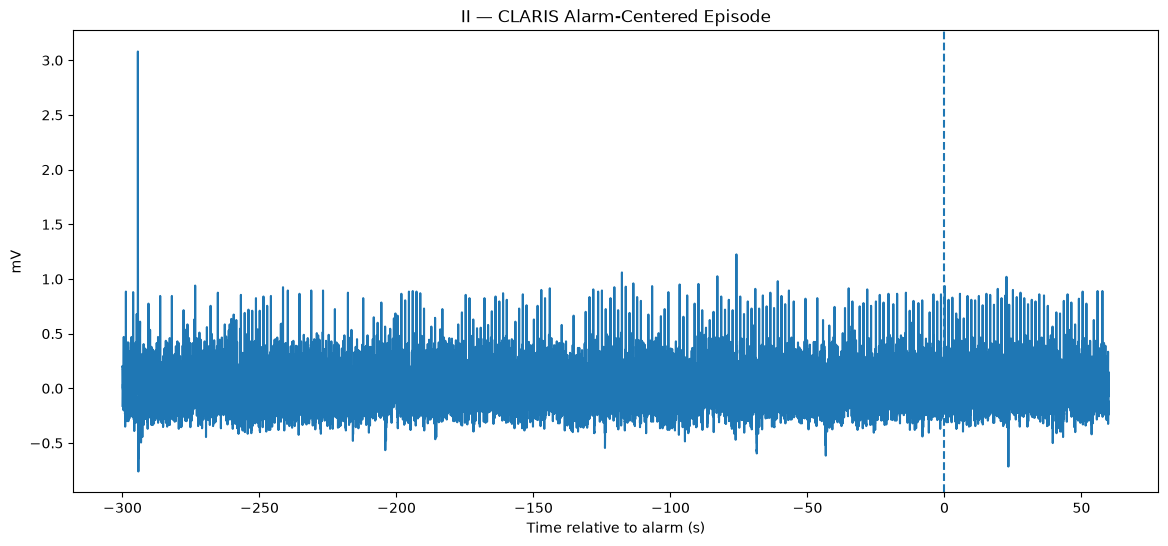

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(episode.time, episode.waveform[:, 0])

plt.axvline(0, linestyle="--")

plt.xlabel("Time relative to alarm (s)")
plt.ylabel(episode.units[0])
plt.title(f"{episode.signals[0]} — CLARIS Alarm-Centered Episode")

plt.show()

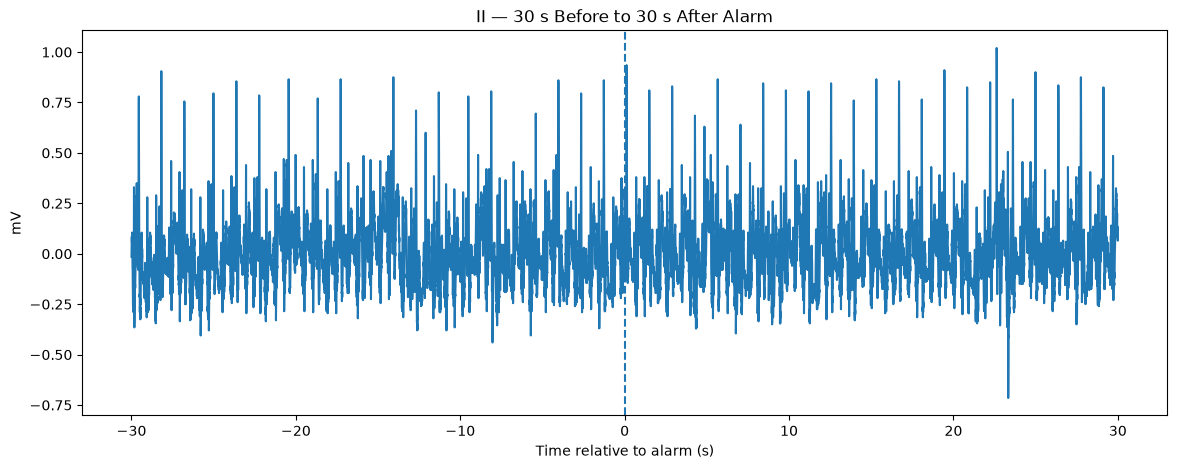

In [24]:
mask = (episode.time >= -30) & (episode.time <= 30)

plt.figure(figsize=(14, 5))

plt.plot(
    episode.time[mask],
    episode.waveform[mask, 0]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Time relative to alarm (s)")
plt.ylabel(episode.units[0])
plt.title(f"{episode.signals[0]} — 30 s Before to 30 s After Alarm")

plt.show()

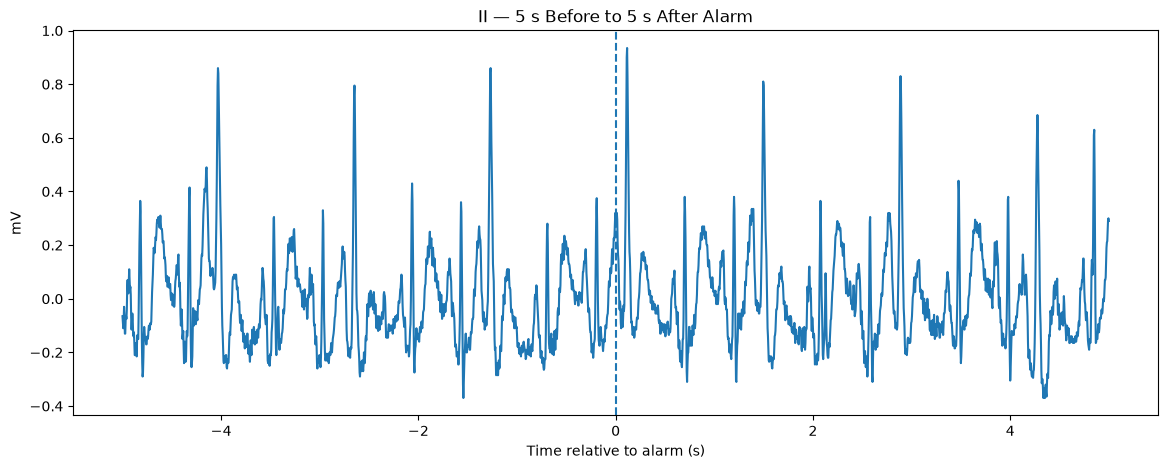

In [25]:
mask = (episode.time >= -5) & (episode.time <= 5)

plt.figure(figsize=(14, 5))

plt.plot(
    episode.time[mask],
    episode.waveform[mask, 0]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Time relative to alarm (s)")
plt.ylabel(episode.units[0])
plt.title(f"{episode.signals[0]} — 5 s Before to 5 s After Alarm")

plt.show()

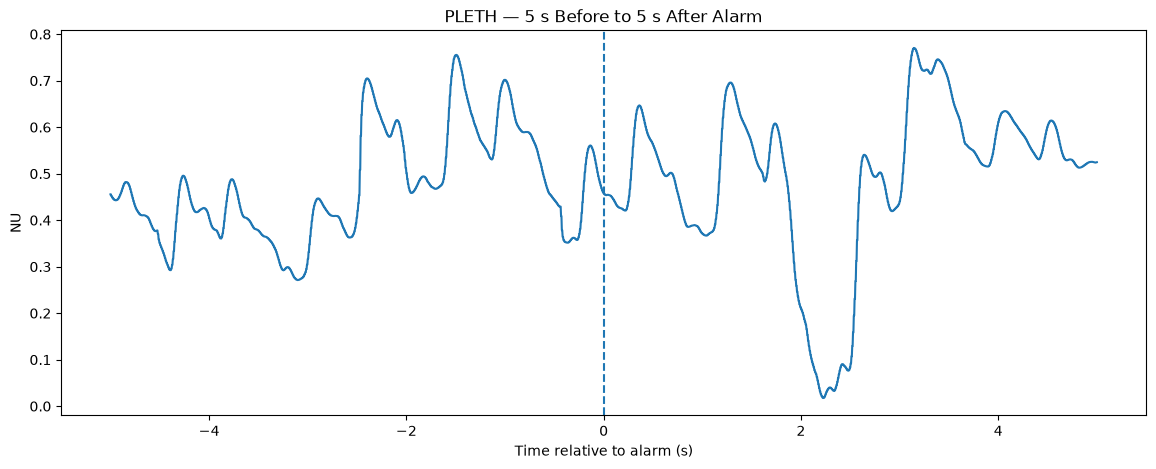

In [26]:
pleth_index = episode.signals.index("PLETH")

mask = (episode.time >= -5) & (episode.time <= 5)

plt.figure(figsize=(14, 5))

plt.plot(
    episode.time[mask],
    episode.waveform[mask, pleth_index]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Time relative to alarm (s)")
plt.ylabel(episode.units[pleth_index])
plt.title("PLETH — 5 s Before to 5 s After Alarm")

plt.show()

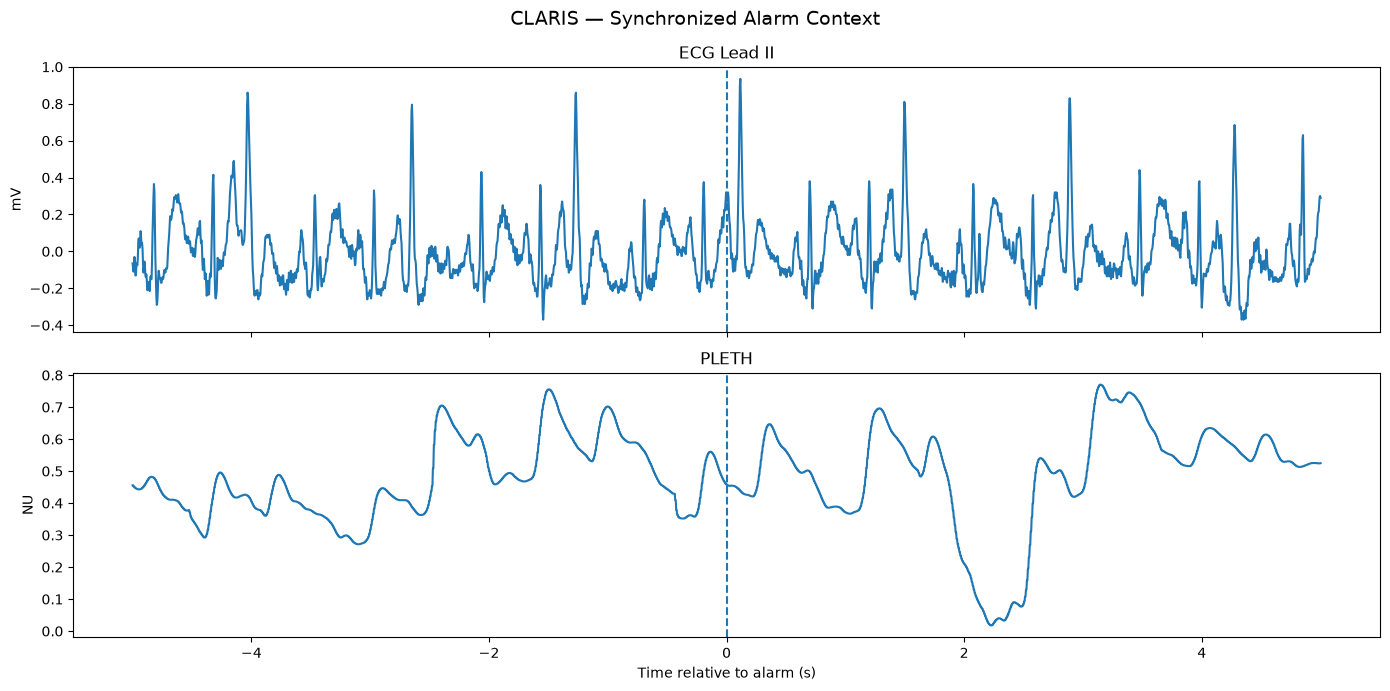

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

mask = (episode.time >= -5) & (episode.time <= 5)

ecg_index = episode.signals.index("II")
pleth_index = episode.signals.index("PLETH")

# ECG
axes[0].plot(
    episode.time[mask],
    episode.waveform[mask, ecg_index]
)
axes[0].axvline(0, linestyle="--")
axes[0].set_ylabel(episode.units[ecg_index])
axes[0].set_title("ECG Lead II")

# PLETH
axes[1].plot(
    episode.time[mask],
    episode.waveform[mask, pleth_index]
)
axes[1].axvline(0, linestyle="--")
axes[1].set_ylabel(episode.units[pleth_index])
axes[1].set_xlabel("Time relative to alarm (s)")
axes[1].set_title("PLETH")

fig.suptitle("CLARIS — Synchronized Alarm Context", fontsize=14)

plt.tight_layout()
plt.show()

In [28]:
for i, signal_name in enumerate(episode.signals):
    signal = episode.waveform[:, i]

    print(
        signal_name,
        "| NaN:", np.isnan(signal).sum(),
        "| Inf:", np.isinf(signal).sum(),
        "| Min:", np.min(signal),
        "| Max:", np.max(signal)
    )

II | NaN: 0 | Inf: 0 | Min: -0.76 | Max: 3.0800215882806476
aVR | NaN: 0 | Inf: 0 | Min: -1.53 | Max: 0.935016717474678
V | NaN: 0 | Inf: 0 | Min: -1.11 | Max: 0.4550092512908779
PLETH | NaN: 0 | Inf: 0 | Min: 0.0 | Max: 0.99951171875


In [29]:
for i, signal_name in enumerate(episode.signals):
    signal = episode.waveform[:, i]

    repeated = np.sum(np.diff(signal) == 0)
    total_transitions = len(signal) - 1
    repeat_fraction = repeated / total_transitions

    print(
        signal_name,
        "| Exact repeated samples:",
        repeated,
        "| Repeat fraction:",
        round(repeat_fraction, 6)
    )

II | Exact repeated samples: 4801 | Repeat fraction: 0.053345
aVR | Exact repeated samples: 8160 | Repeat fraction: 0.090668
V | Exact repeated samples: 13462 | Repeat fraction: 0.149579
PLETH | Exact repeated samples: 45700 | Repeat fraction: 0.507783


In [30]:
for i, signal_name in enumerate(episode.signals):
    signal = episode.waveform[:, i]

    longest_run = 1
    current_run = 1

    for j in range(1, len(signal)):
        if signal[j] == signal[j - 1]:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 1

    longest_duration = (longest_run - 1) / episode.sampling_frequency

    print(
        signal_name,
        "| Longest repeated run:",
        longest_run,
        "samples",
        "| Duration:",
        round(longest_duration, 4),
        "s"
    )

II | Longest repeated run: 4 samples | Duration: 0.012 s
aVR | Longest repeated run: 5 samples | Duration: 0.016 s
V | Longest repeated run: 9 samples | Duration: 0.032 s
PLETH | Longest repeated run: 62 samples | Duration: 0.244 s


In [31]:
window_seconds = 1
window_samples = int(window_seconds * episode.sampling_frequency)

alarm_start = episode.alarm_sample - window_samples
alarm_end = episode.alarm_sample + window_samples

for i, signal_name in enumerate(episode.signals):
    segment = episode.waveform[alarm_start:alarm_end, i]

    print(
        signal_name,
        "| Mean:", round(float(np.mean(segment)), 4),
        "| Std:", round(float(np.std(segment)), 4),
        "| Range:", round(float(np.ptp(segment)), 4)
    )

II | Mean: -0.006 | Std: 0.1713 | Range: 1.245
aVR | Mean: 0.0016 | Std: 0.0993 | Range: 0.765
V | Mean: -0.0015 | Std: 0.0582 | Range: 0.54
PLETH | Mean: 0.4934 | Std: 0.0894 | Range: 0.3501


In [32]:
for i, signal_name in enumerate(episode.signals):
    signal = episode.waveform[:, i]

    min_value = np.min(signal)
    max_value = np.max(signal)

    min_count = np.sum(signal == min_value)
    max_count = np.sum(signal == max_value)

    print(
        signal_name,
        "| At minimum:", min_count,
        "| At maximum:", max_count
    )

II | At minimum: 1 | At maximum: 1
aVR | At minimum: 1 | At maximum: 1
V | At minimum: 1 | At maximum: 1
PLETH | At minimum: 126 | At maximum: 84


In [33]:
import importlib
import src.signal_quality

importlib.reload(src.signal_quality)

from src.signal_quality import calculate_signal_quality_features

print(calculate_signal_quality_features)

<function calculate_signal_quality_features at 0x0000022778A13420>


In [34]:
ecg_index = episode.signals.index("II")

ecg_quality = calculate_signal_quality_features(
    signal=episode.waveform[:, ecg_index],
    sampling_frequency=episode.sampling_frequency,
    alarm_sample=episode.alarm_sample,
    window_seconds=1.0,
)

print(ecg_quality)

{'nan_count': 0, 'inf_count': 0, 'repeat_fraction': 0.05334503716707963, 'longest_repeat_samples': 4, 'longest_repeat_duration': 0.012, 'local_mean': -0.005981323053199693, 'local_std': 0.17128616606014047, 'local_range': 1.245005397070162, 'minimum_count': 1, 'maximum_count': 1}


In [35]:
pleth_index = episode.signals.index("PLETH")

pleth_quality = calculate_signal_quality_features(
    signal=episode.waveform[:, pleth_index],
    sampling_frequency=episode.sampling_frequency,
    alarm_sample=episode.alarm_sample,
    window_seconds=1.0,
)

print(pleth_quality)

{'nan_count': 0, 'inf_count': 0, 'repeat_fraction': 0.5077834198157757, 'longest_repeat_samples': 62, 'longest_repeat_duration': 0.244, 'local_mean': 0.49340543526904923, 'local_std': 0.0893790928904607, 'local_range': 0.3500899074097033, 'minimum_count': 126, 'maximum_count': 84}


In [36]:
quality_features = {}

for i, signal_name in enumerate(episode.signals):
    quality_features[signal_name] = calculate_signal_quality_features(
        signal=episode.waveform[:, i],
        sampling_frequency=episode.sampling_frequency,
        alarm_sample=episode.alarm_sample,
        window_seconds=1.0,
    )

for signal_name, features in quality_features.items():
    print(f"\n{signal_name}")
    for feature, value in features.items():
        print(f"  {feature}: {value}")


II
  nan_count: 0
  inf_count: 0
  repeat_fraction: 0.05334503716707963
  longest_repeat_samples: 4
  longest_repeat_duration: 0.012
  local_mean: -0.005981323053199693
  local_std: 0.17128616606014047
  local_range: 1.245005397070162
  minimum_count: 1
  maximum_count: 1

aVR
  nan_count: 0
  inf_count: 0
  repeat_fraction: 0.09066767408526762
  longest_repeat_samples: 5
  longest_repeat_duration: 0.016
  local_mean: 0.001639231979545677
  local_std: 0.0992823070427078
  local_range: 0.7650000000000001
  minimum_count: 1
  maximum_count: 1

V
  nan_count: 0
  inf_count: 0
  repeat_fraction: 0.14957943977155302
  longest_repeat_samples: 9
  longest_repeat_duration: 0.032
  local_mean: -0.0014801114457831327
  local_std: 0.05820796503354565
  local_range: 0.5400025817555939
  minimum_count: 1
  maximum_count: 1

PLETH
  nan_count: 0
  inf_count: 0
  repeat_fraction: 0.5077834198157757
  longest_repeat_samples: 62
  longest_repeat_duration: 0.244
  local_mean: 0.49340543526904923
  loca

In [37]:
quality_df = pd.DataFrame.from_dict(
    quality_features,
    orient="index"
)

quality_df.index.name = "signal"

quality_df

,nan_count,inf_count,repeat_fraction,longest_repeat_samples,longest_repeat_duration,local_mean,local_std,local_range,minimum_count,maximum_count
signal,,,,,,,,,,
II,0,0,0.053345,4,0.012,-0.005981,0.171286,1.245005,1,1
aVR,0,0,0.090668,5,0.016,0.001639,0.099282,0.765000,1,1
V,0,0,0.149579,9,0.032,-0.001480,0.058208,0.540003,1,1
PLETH,0,0,0.507783,62,0.244,0.493405,0.089379,0.350090,126,84


In [38]:
quality_output_path = "../outputs/003c13_0115_signal_quality.csv"

quality_df.to_csv(quality_output_path)

print(f"Saved to: {quality_output_path}")

Saved to: ../outputs/003c13_0115_signal_quality.csv
